# 02 手書き数字のニューラルネットワーク

学習・予測・評価を行い、中間層の応答を公開された重みから計算します。

必要なライブラリ：NumPy、Matplotlib、scikit-learn

[Google Colabで開く](https://colab.research.google.com/github/m-riho/information-science-interactive-lab/blob/main/public/notebooks/session07/02_digits_mlp.ipynb)

Colabリンクは、このファイルを既存の公開リポジトリへ反映した後に利用できます。

Python 3.12以降を想定し、作者の実行検証はPython 3.13.5で行います。
依存ライブラリは同じフォルダのrequirements.txtを参照してください。
ローカルでは新しい仮想環境で `python -m pip install -r requirements.txt` を実行します。
Colabではランタイム標準ライブラリでも試せますが、版の違いで結果は変わる場合があります。必要ならrequirements.txtに合わせてインストールし、ランタイムを再起動してください。
実行は「ランタイム／カーネル → すべて実行」。保存済みの出力は作者の実測例です。

## データと実験条件

スライド表示51（PPTX内49枚目）の実験に合わせ、64→16→8→10、ReLU、seed7、stratifyありの75％／25％分割、入力を16で割る条件です。講義資料作成コードと同じmax_iter=500を使います。

In [1]:
import sys
import warnings
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
np.random.seed(7)
digits = load_digits()
X, y = digits.data / 16.0, digits.target
train_ids, test_ids = train_test_split(np.arange(len(y)), test_size=.25, stratify=y, random_state=7)
print("訓練:", len(train_ids), "テスト:", len(test_ids), "（分割後は重複なし）")
assert set(train_ids).isdisjoint(test_ids)
print("Python:", sys.version.split()[0], "scikit-learn:", sklearn.__version__)

訓練: 1347 テスト: 450 （分割後は重複なし）
Python: 3.13.5 scikit-learn: 1.9.0


0〜16の画素値を0〜1にします。訓練集合だけで重みを学習し、テスト集合は最後の評価に使います。

## モデルを学習する

小型MLPを訓練します。収束の警告は記録して、無かったことにせず表示します。

更新エポック: 500


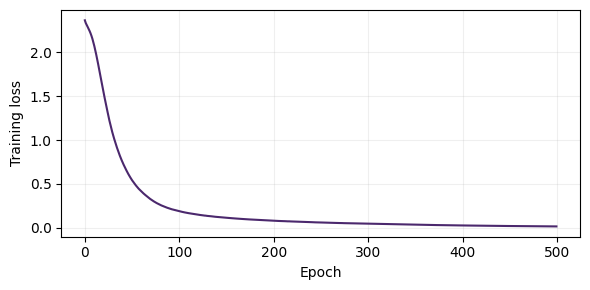

In [2]:
with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    model = MLPClassifier(hidden_layer_sizes=(16,8), activation="relu",
                          max_iter=500, random_state=7).fit(X[train_ids], y[train_ids])
print("更新エポック:", model.n_iter_)
for message in caught:
    print(type(message.message).__name__ + ":", message.message)
assert [w.shape for w in model.coefs_] == [(64,16),(16,8),(8,10)]
plt.figure(figsize=(6,3))
plt.plot(model.loss_curve_, color="#4b286d")
plt.xlabel("Epoch"); plt.ylabel("Training loss"); plt.grid(alpha=.2)
plt.tight_layout(); plt.show()

損失が下がっても、未知データの正解率が必ず上がるわけではありません。上限に達した場合は収束したと断定しません。

## テスト集合で評価する

未学習のデータで正解率・混同行列と誤分類例を表示します。

訓練正解率: 0.9985
テスト正解率: 0.9667


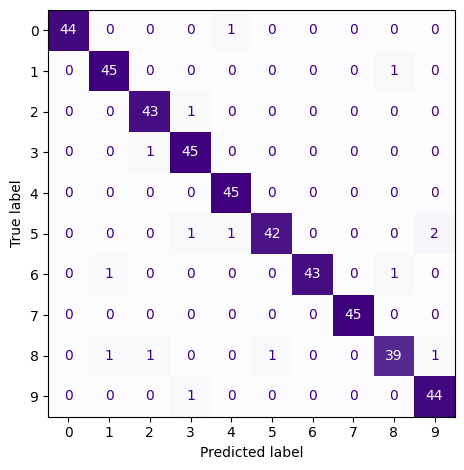

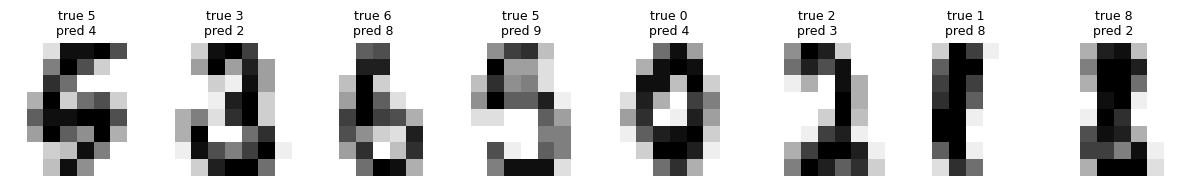

表示した誤分類例: 8


In [3]:
pred = model.predict(X[test_ids])
print("訓練正解率:", round(model.score(X[train_ids], y[train_ids]), 4))
print("テスト正解率:", round(accuracy_score(y[test_ids], pred), 4))
ConfusionMatrixDisplay.from_predictions(y[test_ids], pred, cmap="Purples", colorbar=False)
plt.tight_layout(); plt.show()
wrong = np.flatnonzero(pred != y[test_ids])[:8]
fig, axes = plt.subplots(1, max(1,len(wrong)), figsize=(max(3,len(wrong)*1.5),2))
for ax in np.atleast_1d(axes): ax.axis("off")
for ax, j in zip(np.atleast_1d(axes), wrong):
    ax.imshow(digits.images[test_ids[j]], cmap="gray_r")
    ax.set_title(f"true {y[test_ids[j]]}\npred {pred[j]}", fontsize=9)
plt.tight_layout(); plt.show()
print("表示した誤分類例:", len(wrong))

混同行列の行は正解、列は予測です。誤分類例はモデルの苦手な書き方を考える手掛かりですが、テスト結果を見ながら同じテスト集合向けに調整し続けると、公平な最終評価ではなくなります。

## 中間層の応答を公開APIで再計算する

テスト集合の先頭1枚を選び、coefs_とintercepts_だけを使って、重み付き和→ReLU→重み付き和→ReLU→Softmaxを計算します。

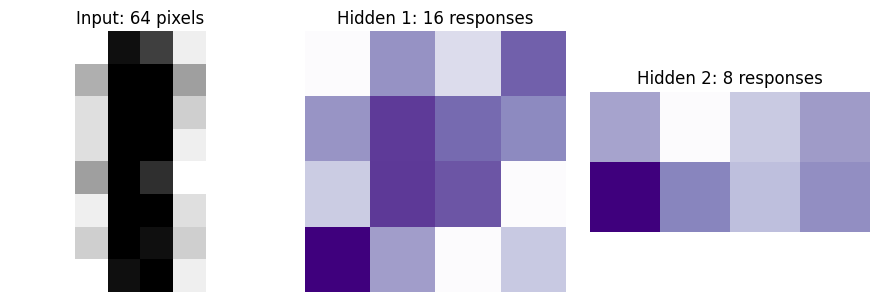

画像の正解: 1 予測: 1
隠れ層1: [[0.    2.681 1.192 3.549 2.636 4.113 3.414 2.859 1.564 4.127 3.716 0.
  5.045 2.454 0.    1.632]]
隠れ層2: [[ 6.702  0.     4.552  7.087 14.299  8.408  5.223  7.847]]


In [4]:
x = X[test_ids[0:1]]
h1 = np.maximum(0, x @ model.coefs_[0] + model.intercepts_[0])
h2 = np.maximum(0, h1 @ model.coefs_[1] + model.intercepts_[1])
logits = h2 @ model.coefs_[2] + model.intercepts_[2]
exp = np.exp(logits - logits.max(axis=1, keepdims=True))
prob = exp / exp.sum(axis=1, keepdims=True)
np.testing.assert_allclose(prob, model.predict_proba(x), atol=1e-10)
assert (h1.shape, h2.shape) == ((1,16), (1,8))
fig, axes = plt.subplots(1,3, figsize=(9,3))
axes[0].imshow(x.reshape(8,8), cmap="gray_r"); axes[0].set_title("Input: 64 pixels")
axes[1].imshow(h1.reshape(4,4), cmap="Purples"); axes[1].set_title("Hidden 1: 16 responses")
axes[2].imshow(h2.reshape(2,4), cmap="Purples"); axes[2].set_title("Hidden 2: 8 responses")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
print("画像の正解:", y[test_ids[0]], "予測:", model.classes_[prob.argmax()])
print("隠れ層1:", np.round(h1,3))
print("隠れ層2:", np.round(h2,3))

16個・8個の応答を便宜的に格子に並べました。CNNの空間的な特徴マップではありません。公開APIのpredict_probaとの一致を確認しました。

## 条件を変える実験は訓練内で比較する

テスト集合を触らず、訓練集合の中をさらに学習・検証に分け、alpha（正則化）の違いを比較します。元のモデルと最終テスト結果は変更しません。

In [5]:
fit_ids, valid_ids = train_test_split(train_ids, test_size=.2, stratify=y[train_ids], random_state=19)
with threadpool_limits(limits=1):
    for alpha in [.0001, .01]:
        with warnings.catch_warnings(record=True) as records:
            warnings.simplefilter("always", ConvergenceWarning)
            trial = MLPClassifier(hidden_layer_sizes=(16,8), activation="relu",
                                  max_iter=500, alpha=alpha, random_state=7).fit(X[fit_ids], y[fit_ids])
        print("alpha", alpha, "訓練", round(trial.score(X[fit_ids], y[fit_ids]),4),
              "検証", round(trial.score(X[valid_ids], y[valid_ids]),4),
              "収束警告数", len(records))

alpha 0.0001 訓練 0.9972 検証 0.9407 収束警告数 1


alpha 0.01 訓練 0.9963 検証 0.9519 収束警告数 1


検証用データは条件を選ぶため、テスト用データは最終性能を測るため、という役割を分けます。ここで最終テストを繰り返し評価しません。

## まとめ

データから重みを学習し、未知の入力を分類できました。中間層も重みと活性化関数による数値変換です。

## 参考資料

- [MLPClassifier 公開属性](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html)
- [scikit-learn ニューラルネットワーク](https://scikit-learn.org/stable/modules/neural_networks_supervised.html)
- [UCI Digits（CC BY 4.0）](https://doi.org/10.24432/C50P49)